# Multi-object detection with YOLOv8 (Section 1 objects)

1. **Dataset:** label each single-object photo with a bounding box, then place the photos side by side in grids from 2×2 to 5×5.
2. **Training:** train YOLOv8 on the grids.
3. **Detection:** given an image with several objects, return the ID and location of each one.

The boxes come from:  

1.   Yolo World
2.   Groudning DINO

Where the two agree, the box is accepted. Everything else, plus a random sample of the accepted boxes, is checked by hand in a review step.


## 1. Setup

In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.4 MB/s eta 0:00:00


In [2]:
import json, shutil, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from ultralytics import YOLO
import ipywidgets as widgets
from IPython.display import display, clear_output
from google.colab import output

from google.colab import drive
drive.mount("/content/drive")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive


In [3]:
# Data
ZIP_PATH = "/content/drive/MyDrive/images.zip"
SPLIT_CSV = "/content/drive/MyDrive/cnn_results/split.csv"   # train/val/test split, made after removing duplicates
SHEET_CSV = "/content/drive/MyDrive/LIST_OF_OBJECTS.csv"
LOCAL_DATA_DIR = "/content/data"                             # the paths in split.csv point here
SECTION = "SECTION - 01"
EXCLUDE_PHOTOS = {"OBJ054_017": "not a photo of the object (per instructions)"}

# Outputs
WORK_DIR = Path("/content/drive/MyDrive/yolo_section1")
PHOTO_DIR = Path("/content/section1_photos")
DET_DIR = Path("/content/detection_data")

# Labelling
PROMPTS = {
    "OBJ001": "basketball",              "OBJ003": "paper notebook",
    "OBJ004": "toy car",                 "OBJ011": "mug",
    "OBJ012": "computer keyboard",       "OBJ015": "water tumbler",
    "OBJ019": "potted plant",            "OBJ020": "metallic earbuds case",
    "OBJ021": "stuffed toy bunny",       "OBJ022": "guitar",
    "OBJ027": "tennis ball",             "OBJ030": "tennis racket",
    "OBJ031": "uno card box",            "OBJ032": "red audio interface box",
    "OBJ034": "table tennis paddle",     "OBJ035": "badminton racket",
    "OBJ036": "long black rectangular case", "OBJ037": "candle",
    "OBJ038": "perfume bottle",          "OBJ039": "scissors",
    "OBJ040": "hair claw clip",          "OBJ041": "table fan",
    "OBJ042": "red triangular case",     "OBJ043": "swimming goggles",
    "OBJ045": "sunglasses",              "OBJ046": "smartwatch",
    "OBJ048": "power bank",              "OBJ052": "spoon",
    "OBJ054": "purse",                   "OBJ055": "black calculator",
    "OBJ057": "black power bank",        "OBJ060": "grey sleep mask",
    "OBJ062": "headphones",              "OBJ063": "bottle with measurement markings",
    "OBJ064": "led light projector",     "OBJ065": "analog wrist watch",
    "OBJ066": "hair oil bottle",         "OBJ073": "bowl",
}
RELABEL_IDS = ["OBJ020", "OBJ032", "OBJ036", "OBJ042", "OBJ055", "OBJ057", "OBJ060"] # objects to label again after changing their prompt
YOLO_WORLD_WEIGHTS = "yolov8x-worldv2.pt"
GDINO_MODEL = "IDEA-Research/grounding-dino-base"
AGREE_IOU = 0.5           # boxes from the two detectors count as agreeing at IoU >= 0.5
SPOT_CHECK_FRAC = 0.05    # share of agreed boxes also checked by hand
SAMPLE_PER_OBJECT = 8
ACCEPT_RATE = 0.9
FULL_REVIEW_IDS = ["OBJ011", "OBJ012", "OBJ020", "OBJ032", "OBJ036", "OBJ042", "OBJ046", "OBJ060"] # objects whose flagged photos are all reviewed on pages instead of using a rule
MAX_EXCLUDED = 0.20

# Grids
TILE = 224
GRIDS = {"2x2": (2, 2), "3x3": (3, 3), "4x4": (4, 4), "5x4": (5, 4), "5x5": (5, 5)}   # (columns, rows)
N_GRIDS = {"train": 1000, "val": 40, "test": 40}

# Training
YOLO_WEIGHTS = "yolov8s.pt"
IMGSZ = 1120
BATCH = 8
EPOCHS = 150
PATIENCE = 30
RUNS_DIR = WORK_DIR / "runs"

SEED = 42
rng = np.random.default_rng(SEED)
WORK_DIR.mkdir(parents=True, exist_ok=True)

## 2. Prepare the photos

Uses the Section 1 objects from the classification split. Duplicates were removed before that split was made, so no copy of a photo appears in more than one of train, validation and test.

In [4]:
data_dir = Path(LOCAL_DATA_DIR)
if not any(data_dir.glob("images_*")):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(data_dir)
    for folder in data_dir.glob("*/images_*"):   # the zip wraps the folders in a parent folder
        shutil.move(folder, data_dir / folder.name)

sheet = pd.read_csv(SHEET_CSV).rename(columns=str.strip)
sheet = sheet[sheet.SECTION.str.strip() == SECTION]
NAMES = dict(zip(sheet.OBJECT_ID.str.strip(), sheet.OBJECT_NAME.str.strip()))
OBJECT_IDS = sorted(NAMES)

split_df = pd.read_csv(SPLIT_CSV)
photos = split_df[split_df.label.isin(OBJECT_IDS) & ~split_df.is_bg].rename(columns={"label": "object_id"})
photos["photo"] = photos.path.map(lambda p: Path(p).stem)
instructed = photos[photos.photo.isin(EXCLUDE_PHOTOS)]
photos = photos[~photos.photo.isin(EXCLUDE_PHOTOS)].reset_index(drop=True)[["photo", "object_id", "split", "path"]]

PHOTO_DIR.mkdir(parents=True, exist_ok=True)
resized = []
for photo, src in zip(photos.photo, photos.path):
    with Image.open(src) as im:
        if im.size == (TILE, TILE):
            shutil.copy(src, PHOTO_DIR / f"{photo}.jpg")
        else:
            resized.append(f"{photo} {im.size}")
            im.resize((TILE, TILE), Image.BILINEAR).save(PHOTO_DIR / f"{photo}.jpg", quality=95)
photos["path"] = [str(PHOTO_DIR / f"{p}.jpg") for p in photos.photo]

counts = photos.split.value_counts()
print(f"{len(OBJECT_IDS)} objects, {len(photos)} photos (train {counts.train}, val {counts.val}, test {counts.test})")
print(f"Left out by instruction: {', '.join(instructed.photo)}")
print(f"Resized to {TILE}x{TILE}: {', '.join(resized)}")

38 objects, 3605 photos (train 2525, val 540, test 540)
Left out by instruction: OBJ054_017
Resized to 224x224: OBJ003_072 (224, 192)


## 3. Label the photos with two detectors

Each photo is run through YOLO-World and Grounding DINO with its object's prompt, and each detector's most confident box is kept. The boxes are saved to `auto_boxes.csv` on Drive, so this only runs once; later runs load the saved file.

The prompts in the config cell are the final ones. Seven objects (OBJ020, OBJ032, OBJ036, OBJ042, OBJ055, OBJ057 and OBJ060) were given more specific prompts after the first review showed that their boxes were often wrong, and were then labelled again.

In [5]:
BOX_A = ["a_x1", "a_y1", "a_x2", "a_y2"]   # YOLO-World
BOX_B = ["b_x1", "b_y1", "b_x2", "b_y2"]   # Grounding DINO

def top_box(scores, boxes):
    if len(scores) == 0:
        return (np.nan,) * 5
    i = int(scores.argmax())
    return (*boxes[i].tolist(), float(scores[i]))

def yolo_world_boxes(model, paths, prompt, batch=16):
    model.set_classes([prompt])
    return [top_box(r.boxes.conf, r.boxes.xyxy)
            for s in range(0, len(paths), batch)
            for r in model.predict(paths[s:s + batch], conf=0.05, verbose=False)]

def gdino_boxes(processor, model, paths, prompt, batch=4):
    out = []
    for s in range(0, len(paths), batch):
        images = [Image.open(p).convert("RGB") for p in paths[s:s + batch]]
        inputs = processor(images=images, text=[prompt + "."] * len(images),
                           return_tensors="pt", padding=True).to("cuda")
        with torch.inference_mode():
            outputs = model(**inputs)
        results = processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=0.25, text_threshold=0.25,
            target_sizes=[(TILE, TILE)] * len(images))
        out += [top_box(r["scores"], r["boxes"]) for r in results]
    torch.cuda.empty_cache()
    return out

def add_status(auto):
    a, b = auto[BOX_A].to_numpy(float), auto[BOX_B].to_numpy(float)
    has_a, has_b = ~np.isnan(a).any(axis=1), ~np.isnan(b).any(axis=1)
    w = np.clip(np.minimum(a[:, 2], b[:, 2]) - np.maximum(a[:, 0], b[:, 0]), 0, None)
    h = np.clip(np.minimum(a[:, 3], b[:, 3]) - np.maximum(a[:, 1], b[:, 1]), 0, None)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    auto["iou"] = w * h / (area(a) + area(b) - w * h)
    auto["status"] = np.select(
        [has_a & has_b & (auto.iou >= AGREE_IOU), has_a & has_b, has_a, has_b],
        ["agree", "disagree", "only YOLO-World", "only Grounding DINO"], "none")
    return auto

In [6]:
auto_csv = WORK_DIR / "auto_boxes.csv"
decisions_json = WORK_DIR / "review_decisions.json"

auto = pd.read_csv(auto_csv) if auto_csv.exists() else None
todo = photos if auto is None else photos[~photos.photo.isin(auto.photo)]

if len(todo):
    import torch
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

    yolo_world = YOLO(YOLO_WORLD_WEIGHTS)
    processor = AutoProcessor.from_pretrained(GDINO_MODEL)
    gdino = AutoModelForZeroShotObjectDetection.from_pretrained(GDINO_MODEL).to("cuda").eval()

    for obj, group in todo.groupby("object_id"):
        a = yolo_world_boxes(yolo_world, list(group.path), PROMPTS[obj])
        b = gdino_boxes(processor, gdino, list(group.path), PROMPTS[obj])
        boxes = pd.DataFrame(np.hstack([a, b]), columns=BOX_A + ["a_conf"] + BOX_B + ["b_conf"])
        auto = pd.concat([auto, pd.concat([group.reset_index(drop=True), boxes], axis=1)], ignore_index=True)
        auto.to_csv(auto_csv, index=False)   # saved per object, so a disconnect loses little

    del yolo_world, gdino
    torch.cuda.empty_cache()

auto = add_status(auto)
auto[BOX_A + BOX_B] = auto[BOX_A + BOX_B].clip(0, TILE)
auto.to_csv(auto_csv, index=False)

by_status = auto.groupby(["object_id", "status"]).size().unstack(fill_value=0)
by_status.insert(0, "prompt", by_status.index.map(PROMPTS))
print(auto.status.value_counts().to_string(), "\n")
print("Photos per object by status. Many 'only Grounding DINO' photos mean YOLO-World missed the object;")
print("many 'disagree' or 'none' photos usually mean a poor prompt.")
print(by_status.sort_values("agree").to_string())

status
agree                  1875
only Grounding DINO    1372
disagree                305
none                     38
only YOLO-World          15 

Photos per object by status. Many 'only Grounding DINO' photos mean YOLO-World missed the object;
many 'disagree' or 'none' photos usually mean a poor prompt.
status                               prompt  agree  disagree  none  only Grounding DINO  only YOLO-World
object_id                                                                                               
OBJ034                  table tennis paddle      0         0     9                   86                0
OBJ037                               candle      6         4     6                   78                1
OBJ064                  led light projector      8        10     1                   75                1
OBJ040                       hair claw clip      9         3     0                   83                0
OBJ020                metallic earbuds case     10        21  

A quick check that each prompt finds the right object: one random photo per object, with the YOLO-World box in red (A) and the Grounding DINO box in blue (B).

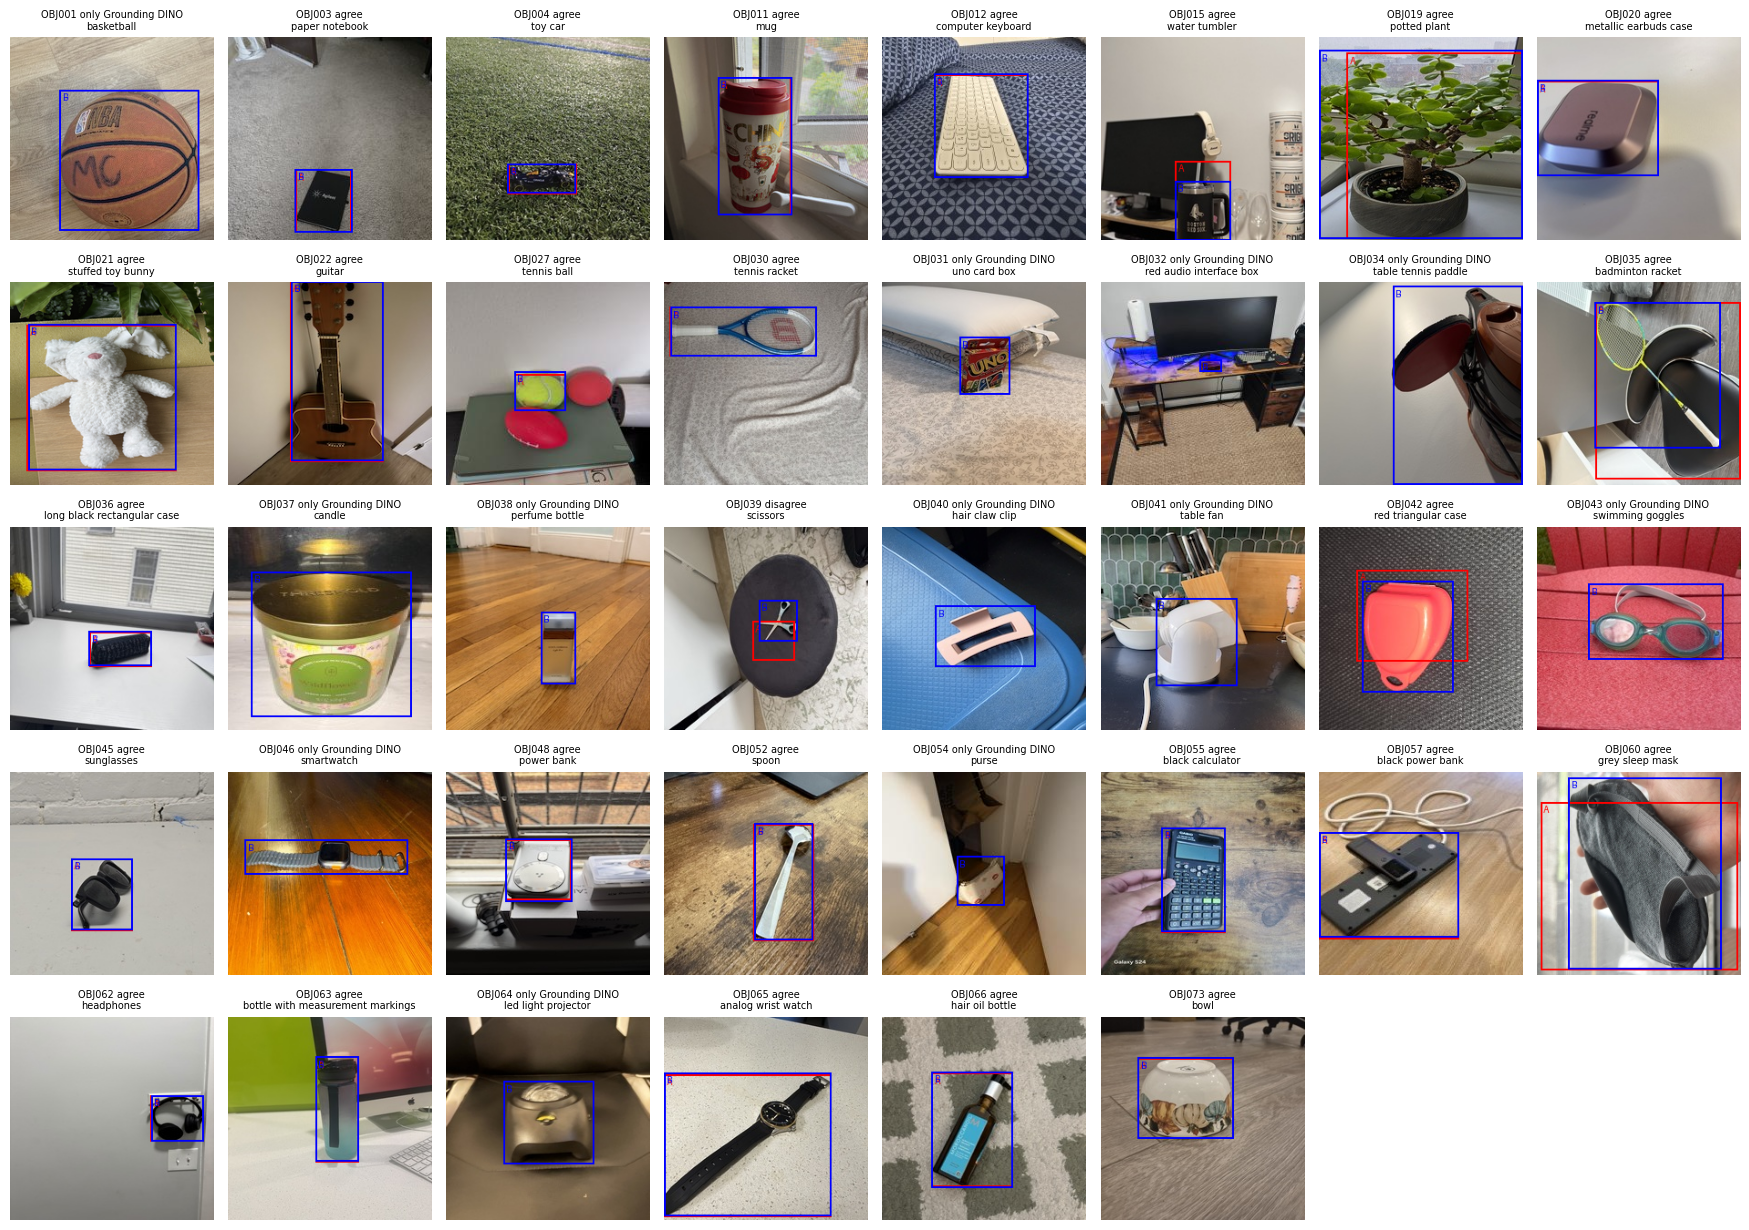

In [8]:
def draw_ab(path, row, scale=1):
    img = Image.open(path).resize((TILE * scale, TILE * scale))
    draw = ImageDraw.Draw(img)
    for cols, color, tag in [(BOX_A, "red", "A"), (BOX_B, "blue", "B")]:
        box = [row[c] * scale for c in cols]
        if not np.isnan(box).any():
            draw.rectangle(box, outline=color, width=2 * scale)
            draw.text((box[0] + 3, box[1] + 2), tag, fill=color)
    return img

sample = auto.groupby("object_id").sample(1, random_state=SEED)
plt.figure(figsize=(17.6, 12.5))
for k, row in enumerate(sample.to_dict("records")):
    plt.subplot(5, 8, k + 1)
    plt.imshow(draw_ab(row["path"], row))
    plt.title(f"{row['object_id']} {row['status']}\n{PROMPTS[row['object_id']]}", fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Review

Reviewing every flagged photo would take too long, so the review is organised per object:

1. **Sample:** 8 random photos from those with a blue (Grounding DINO) box but no agreement, i.e. the "disagree" and "only Grounding DINO" photos. Objects in `FULL_REVIEW_IDS` have all of these photos reviewed instead.
2. **Rule:** if the blue box was right in at least 90% of the sample (with 8 photos, all 8), it's used for the object's remaining photos in that group. Otherwise, the box that was right more often is used.
3. **Gaps:** photos the rule can't cover, because the chosen box is missing, are reviewed individually once the object's sample is done.
4. **Spot check:** a random 5% of the agreed photos, to measure how reliable the automatic boxes are.

The review has two views:

- **Pages:** samples and spot checks, 24 at a time, with the blue box drawn.
- **One at a time:** the ticked photos and the gaps. This keep the red (YOLO-World) or blue (Grounding DINO) box, uses the whole photo, or let's the user draw the box with the two sliders. Excludes a photo only if no box can be drawn, choosing the closest reason for the exclusion report.


In [9]:
RULE_POOL = ["disagree", "only Grounding DINO"]   # photos with a blue box but no agreement

def sample_size(obj, n_photos):
    return n_photos if obj in FULL_REVIEW_IDS else min(SAMPLE_PER_OBJECT, n_photos)

def sample_photos(obj, rows, decisions):
    # earlier reviews count towards the sample, the rest is a random top-up
    reviewed = rows[rows.photo.isin(decisions)]
    others = rows[~rows.photo.isin(decisions)].sample(frac=1, random_state=SEED)
    return list(reviewed.photo) + list(others.photo[:max(0, sample_size(obj, len(rows)) - len(reviewed))])

def object_rules(decisions):
    rules = {}
    pool = auto[auto.status.isin(RULE_POOL)]
    for obj in OBJECT_IDS:
        g = pool[pool.object_id == obj]
        choices = [decisions[p]["choice"] for p in g.photo if p in decisions]
        n, a, b = len(choices), choices.count("A"), choices.count("B")
        if g.empty:
            rule = None
        elif n < sample_size(obj, len(g)):
            rule = "pending"
        elif b / n >= ACCEPT_RATE:
            rule = "B"
        else:
            rule = "A" if a > b else "B"
        rules[obj] = {"rule_photos": len(g), "sampled": n, "blue_correct": b, "red_correct": a, "rule": rule}
    return pd.DataFrame.from_dict(rules, orient="index")

def has_box(row, choice):
    return not np.isnan([row[c] for c in (BOX_A if choice == "A" else BOX_B)]).any()

def rule_choice(row, rule):
    return rule if rule in ("A", "B") and row["status"] != "agree" and has_box(row, rule) else None

spot = auto[auto.status == "agree"].groupby("object_id").sample(frac=SPOT_CHECK_FRAC, random_state=SEED)
decisions = json.loads(decisions_json.read_text()) if decisions_json.exists() else {}
by_photo = auto.set_index("photo", drop=False).to_dict("index")

def save_decisions():
    decisions_json.write_text(json.dumps(decisions, indent=1))

def review_queue():
    rules = object_rules(decisions)
    items = []
    for obj in OBJECT_IDS:
        rows = auto[(auto.object_id == obj) & auto.status.isin(RULE_POOL)]
        items += [(p, "spot check") for p in spot.photo[spot.object_id == obj] if p not in decisions]
        items += [(p, "sample") for p in sample_photos(obj, rows, decisions) if p not in decisions]
    items += [(r["photo"], "gap") for r in auto[auto.status != "agree"].to_dict("records")
              if r["photo"] not in decisions and rules.rule[r["object_id"]] != "pending"
              and rule_choice(r, rules.rule[r["object_id"]]) is None]
    return items

def page_queue():
    return [it for it in review_queue() if it[1] != "gap"]

def detail_queue():
    ticked = [(p, d["kind"]) for p, d in decisions.items() if d["choice"] == "wrong blue"]
    return ticked + [it for it in review_queue() if it[1] == "gap"]

In [10]:
import io
import ipywidgets as widgets
from IPython.display import display
from google.colab import output
output.enable_custom_widget_manager()

def png(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()

def thumbnail(row):
    img = Image.open(row["path"])
    ImageDraw.Draw(img).rectangle([row[c] for c in BOX_B], outline="blue", width=3)
    return png(img)

pages = widgets.VBox()

def show_page():
    remaining = page_queue()
    if not remaining:
        pages.children = [widgets.HTML("<b>Samples and spot checks done.</b> Run the next cell.")]
        return
    page = remaining[:24]
    ticks = [widgets.Checkbox(description="blue box wrong", indent=False) for _ in page]
    tiles = [widgets.VBox([widgets.HTML(f"<small>{by_photo[p]['object_id']} {NAMES[by_photo[p]['object_id']]}"
                                        f"<br>{p} ({kind})</small>"),
                           widgets.Image(value=thumbnail(by_photo[p]), format="png", width=160), tick])
             for (p, kind), tick in zip(page, ticks)]
    confirm = widgets.Button(description="Confirm page", button_style="success")

    def on_confirm(_):
        for (p, kind), tick in zip(page, ticks):
            decisions[p] = {"choice": "wrong blue" if tick.value else "B", "kind": kind}
        save_decisions()
        show_page()

    confirm.on_click(on_confirm)
    pages.children = [widgets.HTML(f"<b>{len(remaining)} left.</b> Tick every photo where the blue box is wrong."),
                      widgets.GridBox(tiles, layout=widgets.Layout(grid_template_columns="repeat(6, 175px)")),
                      confirm]

display(pages)
show_page()

VBox()

In [12]:
CHOICES = [("Keep A (red)", "A"), ("Keep B (blue)", "B"), ("Whole photo", "whole"),
           ("Exclude: not visible", "exclude: object not visible"),
           ("Exclude: no correct box", "exclude: no correct box"),
           ("Exclude: not the object", "exclude: not the object")]
SCALE = 2
info = widgets.HTML()
picture = widgets.Image(format="png", width=TILE * SCALE)
x_range = widgets.IntRangeSlider(min=0, max=TILE, description="left, right", layout=widgets.Layout(width="480px"))
y_range = widgets.IntRangeSlider(min=0, max=TILE, description="top, bottom", layout=widgets.Layout(width="480px"))
history, current = [], None

def render():
    r = by_photo[current[0]]
    img = draw_ab(r["path"], r, scale=SCALE)
    (x1, x2), (y1, y2) = x_range.value, y_range.value
    ImageDraw.Draw(img).rectangle([x1 * SCALE, y1 * SCALE, x2 * SCALE, y2 * SCALE], outline="lime", width=2)
    picture.value = png(img)

def starting_box(r):
    for cols, choice in ((BOX_B, "B"), (BOX_A, "A")):
        if has_box(r, choice):
            return [int(round(r[c])) for c in cols]
    return [0, 0, TILE, TILE]

def show(item=None):
    global current
    remaining = detail_queue()
    current = item or (remaining[0] if remaining else None)
    if current is None:
        info.value = "<b>Review finished.</b>"
        return
    photo, kind = current
    r = by_photo[photo]
    x1, y1, x2, y2 = decisions.get(photo, {}).get("box") or starting_box(r)
    x_range.value, y_range.value = (x1, x2), (y1, y2)
    info.value = (f"<b>{len(remaining)} left</b> &nbsp; {r['object_id']} ({NAMES[r['object_id']]}) &nbsp; {photo} "
                  f"[{kind}: {r['status']}] &nbsp; current choice: {decisions.get(photo, {}).get('choice', '-')}")
    render()

def choose(choice):
    if current is None:
        return
    photo, kind = current
    decision = {"choice": choice, "kind": kind}
    if choice in ("A", "B") and not has_box(by_photo[photo], choice):
        info.value += f" &nbsp; <span style='color:red'>no box {choice} on this photo</span>"
        return
    if choice == "drawn":
        (x1, x2), (y1, y2) = x_range.value, y_range.value
        if x2 - x1 < 5 or y2 - y1 < 5:
            info.value += " &nbsp; <span style='color:red'>the green box is too small</span>"
            return
        decision["box"] = [x1, y1, x2, y2]
    decisions[photo] = decision
    save_decisions()
    history.append(current)
    show()

def button(label, action, style=""):
    b = widgets.Button(description=label, button_style=style, layout=widgets.Layout(width="170px"))
    b.on_click(lambda _: action())
    return b

for slider in (x_range, y_range):
    slider.observe(lambda _: current and render(), names="value")

display(widgets.VBox([
    info,
    widgets.HBox([button(label, lambda c=c: choose(c)) for label, c in CHOICES[:3]] +
                 [button("Back", lambda: history and show(history.pop()))]),
    widgets.HBox([button(label, lambda c=c: choose(c)) for label, c in CHOICES[3:]]),
    picture, x_range, y_range, button("Use green box", lambda: choose("drawn"), "success"),
]))
show()

## 5. Final labels and exclusion report

Reviewed photos use the box picked in the review, agreed boxes are averaged between the two detectors, and the remaining disagreeing photos use their object's rule. Flagged photos that still need a review are left out, so finish the review before building the grids.

In [13]:
decisions = json.loads(decisions_json.read_text())
rules = object_rules(decisions)

def resolve(row):
    a, b = [row[c] for c in BOX_A], [row[c] for c in BOX_B]
    d = decisions.get(row["photo"])
    if d:
        if d["choice"] == "A":
            return a, "reviewed: YOLO-World box"
        if d["choice"] == "B":
            return b, "reviewed: Grounding DINO box"
        if d["choice"] == "drawn":
            return d["box"], "reviewed: drawn by hand"
        return None, d["choice"].removeprefix("exclude: ")
    if row["status"] == "agree":
        return list((np.array(a) + np.array(b)) / 2), "auto: both detectors agree"
    return b, "rule: Grounding DINO box"

resolved = [resolve(r) for r in auto.to_dict("records")]
labels = auto[["photo", "object_id", "split", "path"]].copy()
labels["excluded"] = [box is None for box, _ in resolved]
labels["source"] = [source for _, source in resolved]
labels[["x1", "y1", "x2", "y2"]] = [np.round(box, 1) if box is not None else [np.nan] * 4 for box, _ in resolved]
labels.to_csv(WORK_DIR / "final_labels.csv", index=False)

report = labels.groupby("object_id").agg(photos=("photo", "size"), excluded=("excluded", "sum"))
report["excluded_pct"] = report.excluded / report.photos
reasons = labels[labels.excluded].groupby("object_id").source.agg(
    lambda s: "; ".join(f"{n} {reason}" for reason, n in s.value_counts().items()))
report["reasons"] = reasons.reindex(report.index).fillna("")
report["left_out_by_instruction"] = instructed.groupby("object_id").photo.agg(", ".join).reindex(report.index).fillna("")
report.insert(0, "name", report.index.map(NAMES))
report.to_csv(WORK_DIR / "exclusion_report.csv")

print(labels.source.value_counts().to_string(), "\n")
print(f"Excluded: {labels.excluded.sum()} of {len(labels)} photos ({labels.excluded.mean():.1%})")
print(report.assign(excluded_pct=report.excluded_pct.map("{:.1%}".format)).to_string())

rule_report = rules.copy()
rule_report["rule"] = rule_report.rule.map({"B": "Grounding DINO box"}).fillna("not needed")
rule_report["chosen_correct"] = rule_report.blue_correct
rule_report["photos_by_rule"] = labels[labels.source.str.startswith("rule:")].groupby("object_id").size() \
    .reindex(rule_report.index).fillna(0).astype(int)
rule_report.insert(0, "name", rule_report.index.map(NAMES))
rule_report.to_csv(WORK_DIR / "acceptance_rules.csv")
print("\nRules per object:")
print(rule_report.to_string())

spot_checks = [d for d in decisions.values() if d["kind"] == "spot check"]
print(f"\nSpot check: {sum(d['choice'] in ('A', 'B') for d in spot_checks)} of {len(spot_checks)} "
      "automatically accepted boxes were correct")

source
auto: both detectors agree      1741
rule: Grounding DINO box         882
reviewed: Grounding DINO box     806
reviewed: drawn by hand           79
no correct box                    64
not the object                    20
reviewed: YOLO-World box          13 

Excluded: 84 of 3605 photos (2.3%)
                            name  photos  excluded excluded_pct                             reasons left_out_by_instruction
object_id                                                                                                                  
OBJ001                Basketball      95         0         0.0%                                                            
OBJ003                  NoteBook      95         9         9.5%  6 no correct box; 3 not the object                        
OBJ004                   Toy Car     100         6         6.0%                    6 not the object                        
OBJ011                       mug      93         0         0.0%              

## 6. Build the grid images

Unresized 224×224 photos are placed side by side, with an equal mix of the five grid sizes below and an object in every cell. Each split's grids only use photos from that split, and every photo is used about once before any photo repeats.

| Grid | Objects | Image size |
|---|---|---|
| 2×2 | 4 | 448 × 448 |
| 3×3 | 9 | 672 × 672 |
| 4×4 | 16 | 896 × 896 |
| 5×4 | 20 | 1120 × 896 |
| 5×5 | 25 | 1120 × 1120 |

Labels are written in YOLO format: `class x_center y_center width height`, scaled to 0–1.

In [15]:
SPLIT_SEEDS = {"train": 1, "val": 2, "test": 3}   # fixed per split, so val/test grids don't depend on N_GRIDS["train"]
class_id = {obj: i for i, obj in enumerate(OBJECT_IDS)}
usable = labels[~labels.excluded]

def photo_stream(df, rng):
    # every photo once in random order, then reshuffle
    while True:
        for i in reversed(rng.permutation(df.index)):
            yield df.loc[i]

shutil.rmtree(DET_DIR, ignore_errors=True)
gt_rows = []
for split, n in N_GRIDS.items():
    (DET_DIR / "images" / split).mkdir(parents=True)
    (DET_DIR / "labels" / split).mkdir(parents=True)
    split_rng = np.random.default_rng([SEED, SPLIT_SEEDS[split]])
    split_photos = photo_stream(usable[usable.split == split], split_rng)
    sizes = split_rng.permutation([list(GRIDS)[i % len(GRIDS)] for i in range(n)])

    for i, size in enumerate(sizes):
        cols, rows = GRIDS[size]
        W, H = cols * TILE, rows * TILE
        grid = Image.new("RGB", (W, H))
        name = f"{split}_{i:04d}_{size}"
        lines = []
        for r in range(rows):
            for c in range(cols):
                p = next(split_photos)
                grid.paste(Image.open(p.path), (c * TILE, r * TILE))
                x1, y1, x2, y2 = p.x1 + c * TILE, p.y1 + r * TILE, p.x2 + c * TILE, p.y2 + r * TILE
                lines.append(f"{class_id[p.object_id]} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} "
                             f"{(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
                gt_rows.append({"image": f"{name}.jpg", "split": split, "grid": size, "photo": p.photo,
                                "object_id": p.object_id, "x1": x1, "y1": y1, "x2": x2, "y2": y2})
        grid.save(DET_DIR / "images" / split / f"{name}.jpg", quality=95)
        (DET_DIR / "labels" / split / f"{name}.txt").write_text("\n".join(lines) + "\n")

ground_truth = pd.DataFrame(gt_rows)
ground_truth.to_csv(DET_DIR / "ground_truth.csv", index=False)

(DET_DIR / "data.yaml").write_text(f"path: {DET_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
                                   + "".join(f"  {i}: {obj}\n" for i, obj in enumerate(OBJECT_IDS)))
shutil.make_archive(str(WORK_DIR / "detection_data"), "zip", DET_DIR)   # copy on Drive

summary = ground_truth.groupby("split").agg(images=("image", "nunique"), objects=("photo", "size"),
                                            photos_used=("photo", "nunique"))
summary["uses_per_photo"] = (summary.objects / summary.photos_used).round(2)
print(summary.loc[list(N_GRIDS)].to_string())

       images  objects  photos_used  uses_per_photo
split                                              
train    1000    14800         2464            6.01
val        40      592          528            1.12
test       40      592          529            1.12


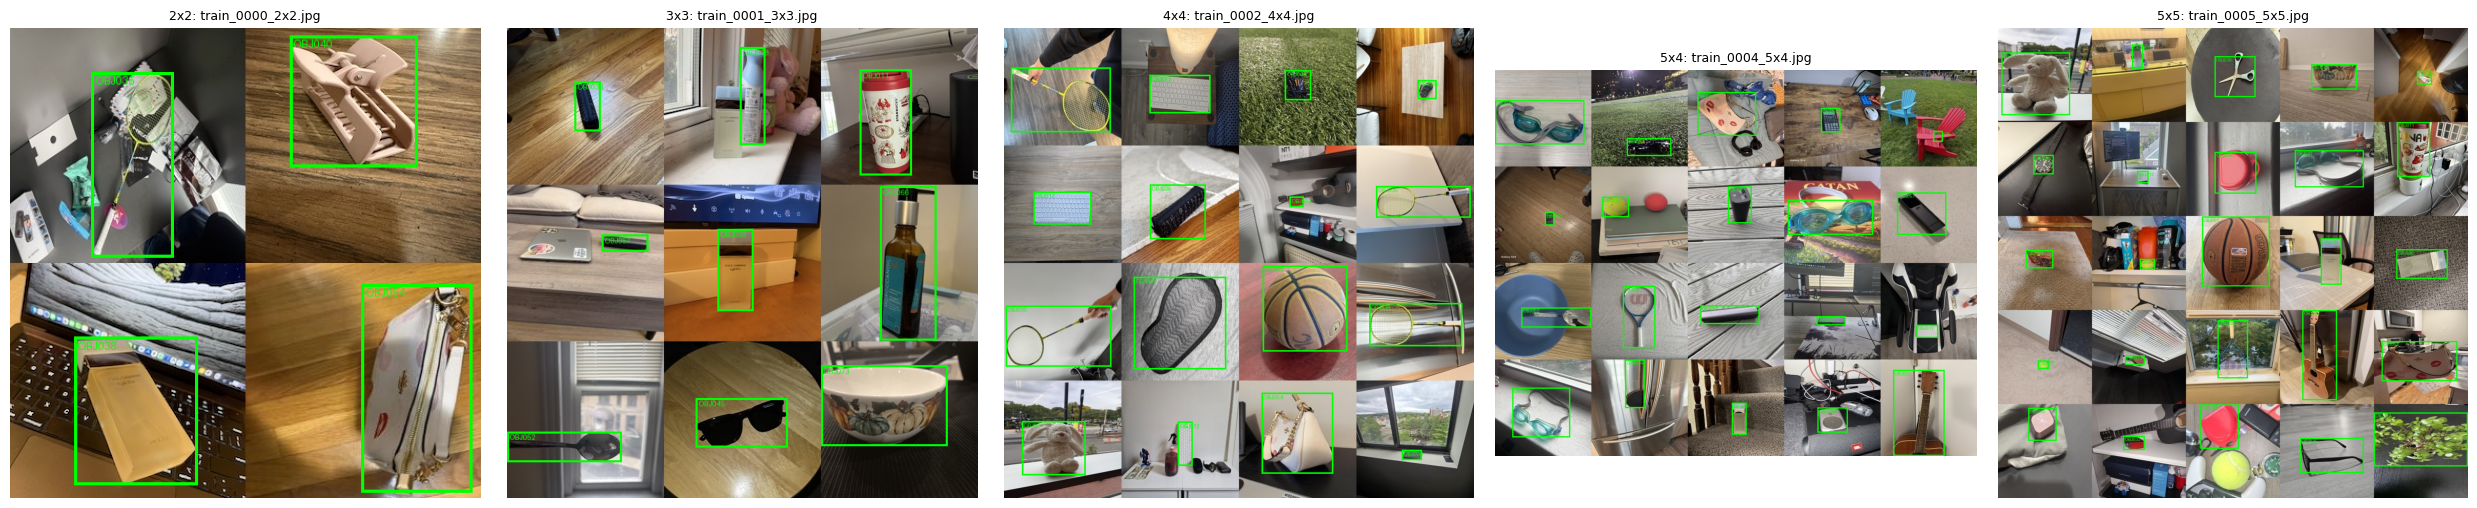

In [16]:
def draw_boxes(img, boxes):
    draw = ImageDraw.Draw(img)
    for label, x1, y1, x2, y2 in boxes:
        draw.rectangle([x1, y1, x2, y2], outline="lime", width=3)
        draw.text((x1 + 4, y1 + 2), label, fill="lime")
    return img

examples = ground_truth[ground_truth.split == "train"].groupby("grid").image.first()
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, (size, name) in zip(axes, examples.items()):
    boxes = ground_truth[ground_truth.image == name][["object_id", "x1", "y1", "x2", "y2"]].values
    ax.imshow(draw_boxes(Image.open(DET_DIR / "images" / "train" / name), boxes))
    ax.set_title(f"{size}: {name}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Train YOLOv8

Fine-tunes COCO-pretrained YOLOv8s at `imgsz=1120`, with YOLO's default training augmentation (mosaic, colour shifts, flips, scaling, translation). Training stops early if validation mAP doesn't improve for 30 epochs. Checkpoints are saved to Drive after every epoch

In [22]:
RUN_NAME = "yolov8s_section1_1000grids"   # use a new name to train again from scratch
run_dir = RUNS_DIR / RUN_NAME
last = run_dir / "weights" / "last.pt"

In [ ]:
RUN_NAME = "yolov8s_section1_1000grids"   # use a new name to train again from scratch
run_dir = RUNS_DIR / RUN_NAME
last = run_dir / "weights" / "last.pt"

def finished(run_dir):
    # a run is done when it reached EPOCHS or early stopping ended it
    if not (run_dir / "results.csv").exists():
        return False
    curves = pd.read_csv(run_dir / "results.csv")
    curves.columns = curves.columns.str.strip()
    best_epoch = int(curves.epoch[curves["metrics/mAP50-95(B)"].idxmax()])
    return len(curves) >= EPOCHS or len(curves) - best_epoch > PATIENCE

if finished(run_dir):
    print(f"{RUN_NAME} has already finished training. Set a new RUN_NAME to train again.")
elif last.exists():
    YOLO(last).train(resume=True)
else:
    YOLO(YOLO_WEIGHTS).train(data=str(DET_DIR / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                             patience=PATIENCE, seed=SEED, project=str(RUNS_DIR), name=RUN_NAME,
                             exist_ok=True)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/detection_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1120, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_section1_1000grids, nbs=64, nms=None, opset=None

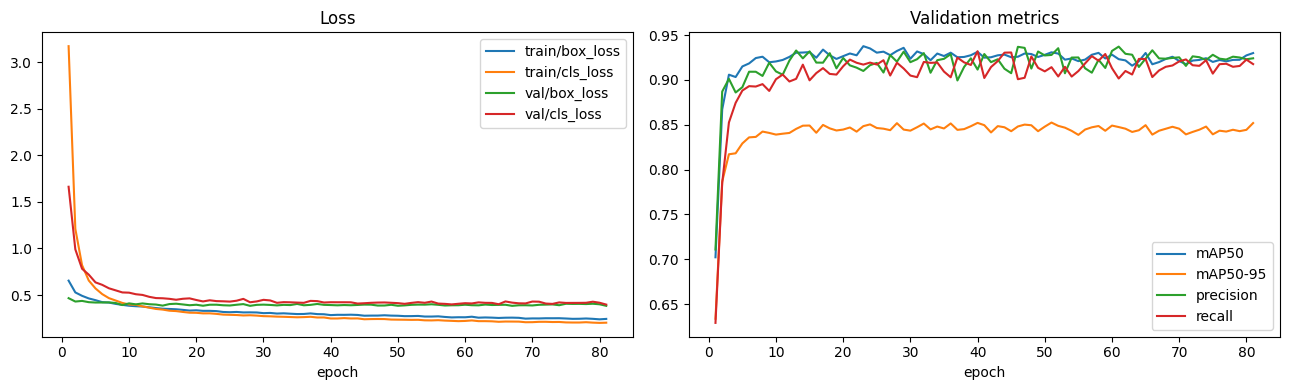

In [ ]:
curves = pd.read_csv(run_dir / "results.csv")
curves.columns = curves.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col in ["train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss"]:
    axes[0].plot(curves.epoch, curves[col], label=col)
axes[0].set_title("Loss")
for col in ["metrics/mAP50(B)", "metrics/mAP50-95(B)", "metrics/precision(B)", "metrics/recall(B)"]:
    axes[1].plot(curves.epoch, curves[col], label=col.split("/")[1].removesuffix("(B)"))
axes[1].set_title("Validation metrics")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Evaluate on the test grids

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,140,290 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2210.3±642.9 MB/s, size: 241.7 KB)
val: Scanning /content/detection_data/labels/test... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 2.0Kit/s 0.0s
val: New cache created: /content/detection_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.1s/it 5.3s
                   all         40        592      0.931      0.899      0.923      0.858
Speed: 42.4ms preprocess, 37.0ms inference, 0.0ms loss, 7.3ms postprocess per image
Results saved to /content/drive/MyDrive/yolo_section1/runs/test_eval
mAP50 0.923 | mAP50-95 0.858 | precision 0.931 | recall 0.899

Hardest objects (lowest AP50-95):
object_id                name  precision  recall  AP50  AP50-95
   OBJ065        Analog wat

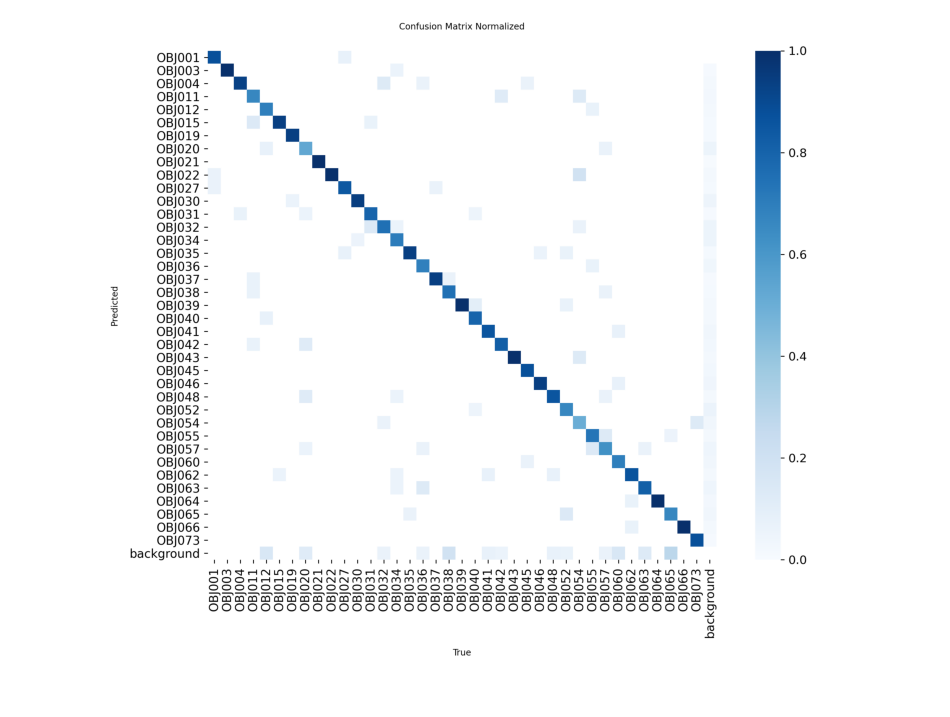

In [23]:
model = YOLO(run_dir / "weights" / "best.pt")
metrics = model.val(data=str(DET_DIR / "data.yaml"), split="test", imgsz=IMGSZ, batch=BATCH,
                    project=str(RUNS_DIR), name="test_eval", exist_ok=True, verbose=False)
print(f"mAP50 {metrics.box.map50:.3f} | mAP50-95 {metrics.box.map:.3f} | "
      f"precision {metrics.box.mp:.3f} | recall {metrics.box.mr:.3f}")

ids = [model.names[int(i)] for i in metrics.box.ap_class_index]
per_class = pd.DataFrame({"object_id": ids, "name": [NAMES[i] for i in ids],
                          "precision": metrics.box.p, "recall": metrics.box.r,
                          "AP50": metrics.box.ap50, "AP50-95": metrics.box.ap}).round(3)
per_class.to_csv(WORK_DIR / "test_per_class.csv", index=False)
print("\nHardest objects (lowest AP50-95):")
print(per_class.sort_values("AP50-95").head(10).to_string(index=False))

cm_path = RUNS_DIR / "test_eval" / "confusion_matrix_normalized.png"
if cm_path.exists():
    plt.figure(figsize=(12, 12))
    plt.imshow(Image.open(cm_path))
    plt.axis("off")
    plt.show()

## 9. Detect objects in an image

It returns the ID, confidence and box corners (in pixels of the input image) of every object found, plus the image with the boxes drawn on it. A detection counts as correct when its ID is right and its box overlaps the true box with IoU ≥ 0.5.

In [24]:
def detect(image, conf=0.25):
    r = model.predict(image, imgsz=IMGSZ, conf=conf, verbose=False)[0]
    xyxy = r.boxes.xyxy.cpu().numpy().round().astype(int)
    found = pd.DataFrame({"object_id": [r.names[int(c)] for c in r.boxes.cls],
                          "confidence": r.boxes.conf.cpu().numpy().round(3),
                          "x1": xyxy[:, 0], "y1": xyxy[:, 1], "x2": xyxy[:, 2], "y2": xyxy[:, 3]})
    return found, r.plot()[:, :, ::-1]

def iou(a, b):
    w = min(a[2], b[2]) - max(a[0], b[0])
    h = min(a[3], b[3]) - max(a[1], b[1])
    inter = max(w, 0) * max(h, 0)
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

def match(found, truth, min_iou=0.5):
    used, correct = set(), 0
    for p in found.itertuples():
        for t in truth.itertuples():
            if t.Index not in used and p.object_id == t.object_id and \
               iou((p.x1, p.y1, p.x2, p.y2), (t.x1, t.y1, t.x2, t.y2)) >= min_iou:
                used.add(t.Index)
                correct += 1
                break
    return correct

In [25]:
rows = []
for img_path in sorted((DET_DIR / "images" / "test").glob("*.jpg")):
    found, _ = detect(img_path)
    truth = ground_truth[ground_truth.image == img_path.name]
    correct = match(found, truth)
    rows.append({"image": img_path.name, "grid": truth.grid.iloc[0], "objects": len(truth), "correct": correct,
                 "false_detections": len(found) - correct})

per_image = pd.DataFrame(rows)
per_image["all_correct"] = (per_image.correct == per_image.objects) & (per_image.false_detections == 0)
by_grid = per_image.groupby("grid").agg(images=("image", "size"), objects=("objects", "sum"),
                                        correct=("correct", "sum"), false_detections=("false_detections", "sum"),
                                        all_correct=("all_correct", "mean"))
by_grid.loc["total"] = by_grid.sum()
by_grid.loc["total", "all_correct"] = per_image.all_correct.mean()
by_grid["found"] = by_grid.correct / by_grid.objects
print(by_grid.assign(found=by_grid.found.map("{:.1%}".format),
                     all_correct=by_grid.all_correct.map("{:.1%}".format)).to_string())

       images  objects  correct  false_detections all_correct  found
grid                                                                
2x2       8.0     32.0     29.0               8.0       12.5%  90.6%
3x3       8.0     72.0     63.0               9.0       12.5%  87.5%
4x4       8.0    128.0    120.0              11.0       12.5%  93.8%
5x4       8.0    160.0    147.0              10.0        0.0%  91.9%
5x5       8.0    200.0    182.0              22.0        0.0%  91.0%
total    40.0    592.0    541.0              60.0        7.5%  91.4%


In [ ]:
import yaml

for split in ["train", "val", "test"]:
    print(f"{split} grids on disk: {len(list((DET_DIR / 'images' / split).glob('*.jpg')))}")

runs = sorted(p for p in RUNS_DIR.iterdir() if (p / "results.csv").exists() and (p / "weights" / "best.pt").exists())
comparison = []
for run in runs:
    args = yaml.safe_load(open(run / "args.yaml"))
    curves = pd.read_csv(run / "results.csv")
    curves.columns = curves.columns.str.strip()
    best = curves.loc[curves["metrics/mAP50-95(B)"].idxmax()]
    m = YOLO(run / "weights" / "best.pt")
    res = m.val(data=str(DET_DIR / "data.yaml"), split="test", imgsz=IMGSZ, batch=BATCH, project=str(RUNS_DIR),
                name=f"test_{run.name}", exist_ok=True, verbose=False, plots=False)
    comparison.append({"run": run.name, "imgsz": args["imgsz"], "epochs_run": len(curves),
                       "best_epoch": int(best.epoch), "val_mAP50_in_training": round(best["metrics/mAP50(B)"], 3),
                       "test_mAP50": round(res.box.map50, 3), "test_mAP50-95": round(res.box.map, 3),
                       "test_precision": round(res.box.mp, 3), "test_recall": round(res.box.mr, 3)})

print(pd.DataFrame(comparison).to_string(index=False))

train grids on disk: 1000
val grids on disk: 40
test grids on disk: 40
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,140,290 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2401.5±912.1 MB/s, size: 275.3 KB)
val: Scanning /content/detection_data/labels/test.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 12.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.4it/s 2.1s
                   all         40        592      0.876      0.739      0.814      0.739
Speed: 3.3ms preprocess, 35.7ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,140,290 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2912.8±804.7 MB/s, size: 360.2

In [ ]:
for run in runs:
    c = pd.read_csv(run / "results.csv")
    c.columns = c.columns.str.strip()
    if "time" in c:
        print(f"{run.name}: {c.time.iloc[-1] / len(c):.0f} seconds per epoch")
    else:
        print(f"{run.name}: no time column; check its training log for 'train: Scanning ... N images'")

yolov8s_section1: 1 seconds per epoch
yolov8s_section1_1000grids: 50 seconds per epoch
yolov8s_section1_fixed200: 13 seconds per epoch


outcome
correct               540
missed                 35
extra (on nothing)     33
box misplaced          14
extra (duplicate)      11
wrong ID                3 

Wrong ID: OBJ034 -> OBJ045, OBJ034 -> OBJ046, OBJ055 -> OBJ003
outcome  box misplaced  correct  extra (duplicate)  extra (on nothing)  missed  wrong ID  errors
object                                                                                          
OBJ065               3       11                  0                   3       4         0      10
OBJ020               3       11                  0                   2       3         0       8
OBJ038               0       12                  0                   4       4         0       8
OBJ034               1       11                  1                   0       3         2       7
OBJ057               0       14                  0                   4       2         0       6
OBJ052               0       12                  1                   2       3         0    

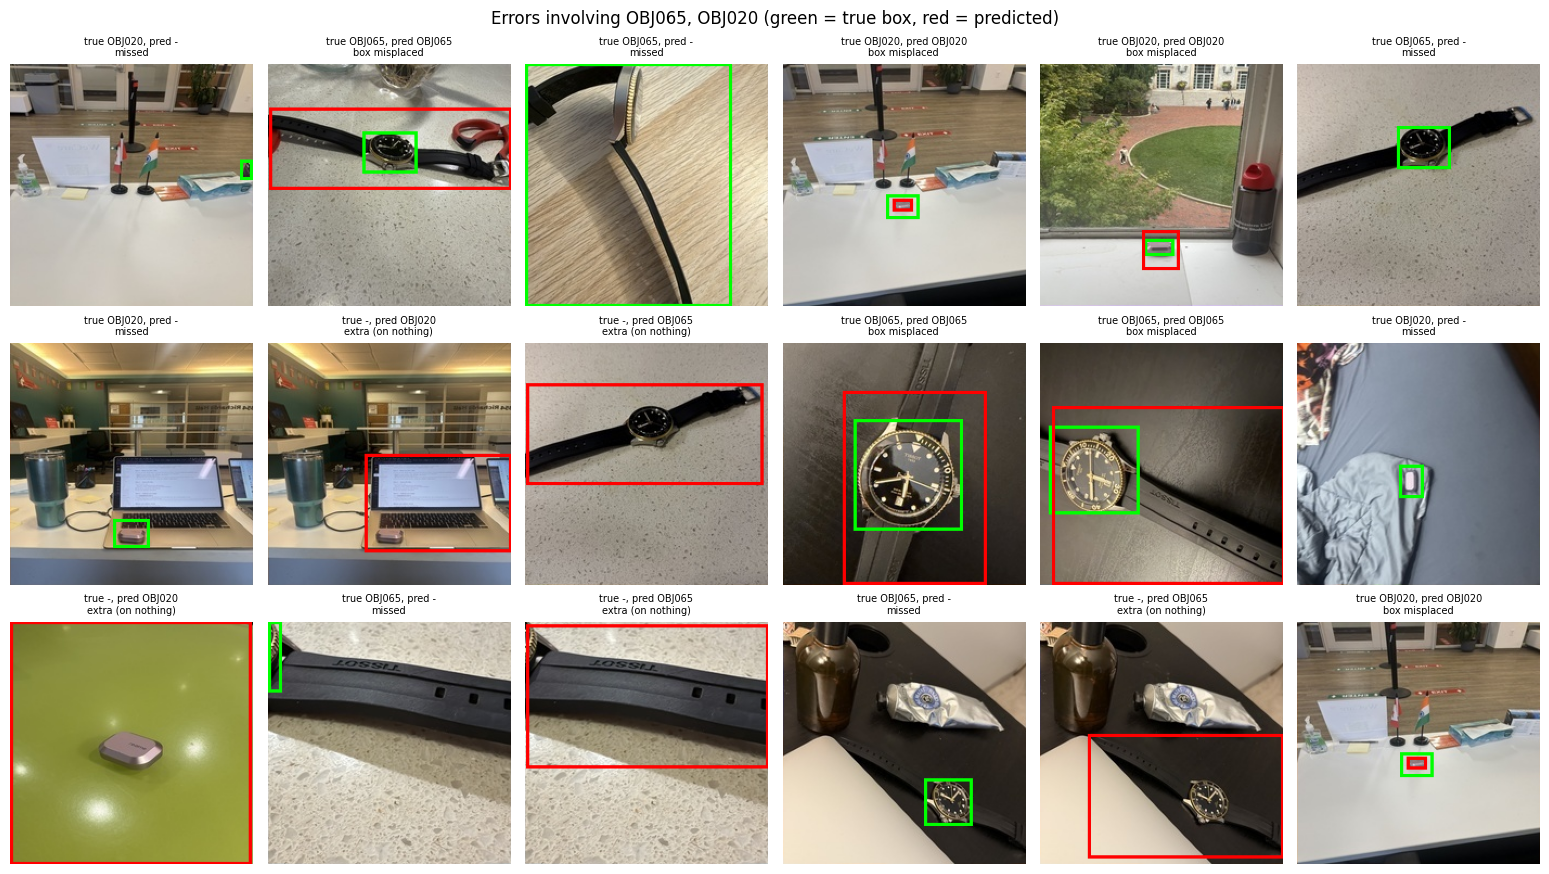

In [26]:
FOCUS = ["OBJ065", "OBJ020"]

# match every true object to the prediction that overlaps it most, whatever its class
rows = []
for img in sorted((DET_DIR / "images" / "test").glob("*.jpg")):
    found = detect(img)[0]
    preds = list(zip(found.object_id, found[["x1", "y1", "x2", "y2"]].values))
    truth = ground_truth[ground_truth.image == img.name]
    used = set()
    for t in truth.itertuples():
        true_box = (t.x1, t.y1, t.x2, t.y2)
        best_iou, best = max(((iou(b, true_box), i) for i, (_, b) in enumerate(preds) if i not in used),
                             default=(0, None))
        if best_iou >= 0.5:
            outcome = "correct" if preds[best][0] == t.object_id else "wrong ID"
        elif best_iou >= 0.1:
            outcome = "box misplaced"
        else:
            outcome, best = "missed", None
        if best is not None:
            used.add(best)
        rows.append({"image": img.name, "true": t.object_id, "predicted": preds[best][0] if best is not None else "-",
                     "outcome": outcome, "true_box": true_box, "pred_box": preds[best][1] if best is not None else None})
    for i, (label, b) in enumerate(preds):
        if i not in used:
            near = max((iou(b, (t.x1, t.y1, t.x2, t.y2)) for t in truth.itertuples()), default=0)
            rows.append({"image": img.name, "true": "-", "predicted": label,
                         "outcome": "extra (duplicate)" if near >= 0.1 else "extra (on nothing)",
                         "true_box": None, "pred_box": b})

errors = pd.DataFrame(rows)
errors["object"] = errors.true.where(errors.true != "-", errors.predicted)
table = pd.crosstab(errors.object, errors.outcome)
table["errors"] = table.drop(columns="correct").sum(axis=1)

print(errors.outcome.value_counts().to_string(), "\n")
print("Wrong ID:", ", ".join(f"{t} -> {p}" for t, p in errors[errors.outcome == "wrong ID"][["true", "predicted"]].values))
print(table.sort_values("errors", ascending=False).head(10).to_string())

def cell_crop(row):
    box = row["true_box"] or row["pred_box"]
    x0, y0 = int((box[0] + box[2]) / 2 // TILE) * TILE, int((box[1] + box[3]) / 2 // TILE) * TILE
    img = Image.open(DET_DIR / "images" / "test" / row["image"]).crop((x0, y0, x0 + TILE, y0 + TILE))
    draw = ImageDraw.Draw(img)
    for b, color in [(row["true_box"], "lime"), (row["pred_box"], "red")]:
        if b is not None:
            draw.rectangle([b[0] - x0, b[1] - y0, b[2] - x0, b[3] - y0], outline=color, width=3)
    return img

shown = errors[(errors.object.isin(FOCUS) | errors.predicted.isin(FOCUS)) & (errors.outcome != "correct")].head(24)
plt.figure(figsize=(15.6, 3 * -(-len(shown) // 6)))
for k, row in enumerate(shown.to_dict("records")):
    plt.subplot(-(-len(shown) // 6), 6, k + 1)
    plt.imshow(cell_crop(row))
    plt.title(f"true {row['true']}, pred {row['predicted']}\n{row['outcome']}", fontsize=7)
    plt.axis("off")
plt.suptitle(f"Errors involving {', '.join(FOCUS)} (green = true box, red = predicted)")
plt.tight_layout()
plt.show()